# Treino — LateFusionSpatialCNN 11×11 — Ensemble standard + loss ponderada para alturas altas

Este notebook testa o modelo **LateFusionCNN** no patch **11×11**, mantendo a arquitetura e a validação usadas anteriormente, mas substituindo o sampler por uma **loss ponderada**.

Experiências incluídas:

1. **Ensemble standard**, sem ponderação da loss.
2. **Ensemble com penalização extra para alturas altas**, por exemplo `y >= 20 m`.
3. Opcionalmente, **loss contínua**, onde o peso cresce gradualmente com a altura.

Objetivo: verificar se é possível reduzir a subestimação das alturas altas sem degradar demasiado o RMSE global.


In [17]:
# ============================================================
# 1. IMPORTS E CONFIGURAÇÃO GLOBAL
# ============================================================

import os
import time
import json
import re
import random
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rasterio
import geopandas as gpd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# -----------------------------
# Caminhos
# -----------------------------
# Pasta que contém:
#   patch_3x3/
#   patch_5x5/
#   patch_7x7/
#   patch_11x11/
#   patch_15x15/
PATCH_BASE_DIR = Path(r"D:\Tese_data_refinada\_example_patches_by_size")
VALIDATION_DIR = Path(r"D:\Tese_data_refinada\Areas_gpkg")

OUTPUT_BASE_DIR = Path("outputs_fch/spacial_cnn/late_fusion_cnn_11x11_high_weight_loss_ensemble")
OUTPUT_BASE_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR = OUTPUT_BASE_DIR
PLOTS_DIR = OUTPUT_BASE_DIR / "figuras"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# -----------------------------
# Experiência
# -----------------------------
SEED = 42
TARGET_COLUMN = "rh_opt_098"
TARGET_SCALE = 100.0   # cm → metros

# Patch escolhido a partir da experiência de ablação.
PATCH_SIZE_TO_USE = 11
RAW_BASE_DIR = PATCH_BASE_DIR / f"patch_{PATCH_SIZE_TO_USE}x{PATCH_SIZE_TO_USE}"

# Cross-validation
N_SPLITS = 5
N_HEIGHT_BINS = 5

# Mantém a mesma configuração usada nos teus testes anteriores.
AUGMENTATION_MODE = "aug_on"

# Experiências deste notebook.
# RUN_STANDARD_ENSEMBLE: repete o baseline standard com as mesmas seeds.
# RUN_HIGH_HEIGHT_WEIGHTED_LOSS: usa MSE ponderado para y >= HIGH_HEIGHT_THRESHOLD_M.
# RUN_CONTINUOUS_HEIGHT_WEIGHTED_LOSS: usa MSE ponderado continuamente com a altura.
RUN_STANDARD_ENSEMBLE = True
RUN_HIGH_HEIGHT_WEIGHTED_LOSS = True
RUN_CONTINUOUS_HEIGHT_WEIGHTED_LOSS = False

# Pesos para alturas altas.
# Se ficar demasiado pesado, começa só com [1.5].
HIGH_HEIGHT_THRESHOLD_M = 20.0
HIGH_HEIGHT_WEIGHTS_TO_RUN = [1.5, 2.0]

# Loss contínua opcional: weight = 1 + alpha * (y / y_max_train)
# Por defeito fica desligada. Para testar, por exemplo: CONTINUOUS_HEIGHT_ALPHAS_TO_RUN = [0.5, 1.0]
CONTINUOUS_HEIGHT_ALPHAS_TO_RUN = []

# Seeds usadas em cada ensemble.
ENSEMBLE_SEEDS = [42, 123, 2024]

# Classes fixas para métricas por altura.
# Valores em metros: 0-5, 5-10, 10-15, 15-20, >20.
FIXED_HEIGHT_BINS_M = [0, 5, 10, 15, 20, np.inf]

# Plots
PLOT_EACH_FOLD = False
SAVE_PLOTS = True

# -----------------------------
# Hiperparâmetros
# -----------------------------
BATCH_SIZE = 64
LR = 3e-4
WEIGHT_DECAY = 0.0
EPOCHS = 70
PATIENCE = 15
LOG_EVERY = 5      # imprime métricas completas a cada N épocas

# -----------------------------
# Hardware
# -----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM disponível: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

print(f"\nPatch usado: {PATCH_SIZE_TO_USE}x{PATCH_SIZE_TO_USE}")
print(f"Área aproximada: {PATCH_SIZE_TO_USE * 25} m × {PATCH_SIZE_TO_USE * 25} m")
print(f"Pasta de entrada: {RAW_BASE_DIR}")
print(f"Pasta de saída:   {OUTPUT_BASE_DIR}")
print(f"Bins fixos de altura (m): {FIXED_HEIGHT_BINS_M}")
print(f"Pesos para alturas >= {HIGH_HEIGHT_THRESHOLD_M} m: {HIGH_HEIGHT_WEIGHTS_TO_RUN}")


Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3060
VRAM disponível: 12.9 GB

Patch usado: 11x11
Área aproximada: 275 m × 275 m
Pasta de entrada: D:\Tese_data_refinada\_example_patches_by_size\patch_11x11
Pasta de saída:   outputs_fch\spacial_cnn\late_fusion_cnn_11x11_high_weight_loss_ensemble
Bins fixos de altura (m): [0, 5, 10, 15, 20, inf]
Pesos para alturas >= 20.0 m: [1.5, 2.0]


In [18]:
# ============================================================
# 2. DATASET E AUGMENTATION
# ============================================================

class FCHDataset(Dataset):
    def __init__(self, X, y, transform=None):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.float32)
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx].copy()
        if self.transform is not None:
            x = self.transform(x)
        return (
            torch.tensor(x, dtype=torch.float32),
            torch.tensor(self.y[idx], dtype=torch.float32),
        )


def base_augmentation(x):
    """Rotações e flips aleatórios. Usar apenas no treino."""
    k = np.random.randint(0, 4)
    if k > 0:
        x = np.rot90(x, k, axes=(1, 2)).copy()

    if np.random.rand() > 0.5:
        x = np.flip(x, axis=2).copy()

    if np.random.rand() > 0.5:
        x = np.flip(x, axis=1).copy()

    return x


def get_train_transform(augmentation_mode):
    """Devolve a transformação de treino para a experiência de ablation."""
    if augmentation_mode == "aug_on":
        return base_augmentation

    if augmentation_mode == "aug_off":
        return None

    raise ValueError(
        f"augmentation_mode inválido: {augmentation_mode}. "
        "Usa 'aug_on' ou 'aug_off'."
    )


In [19]:
# ============================================================
# 3. CARREGAMENTO DOS TIFs
# ============================================================

def extract_point_id(filename):
    m = re.search(r"point_(\d+)_", filename)
    if m is None:
        raise ValueError(f"Não consegui extrair point_id de: {filename}")
    return int(m.group(1))


def build_target_dict(gdf, target_column):
    possible_id_cols = ["point_id", "POINT_ID", "id", "ID", "fid", "FID"]
    id_col = next((c for c in possible_id_cols if c in gdf.columns), None)

    ids = gdf[id_col].astype(int).values if id_col else gdf.index.astype(int).values
    targets = gdf[target_column].values

    return {
        int(pid): float(t)
        for pid, t in zip(ids, targets)
        if not pd.isna(t)
    }


def canonical_band_name(name):
    """
    Normaliza nomes de bandas para comparar regiões.

    Remove:
      - prefixo da área, se existir antes de 20200000;
      - sufixos técnicos que não mudam a variável, como _A e _Mosaic.

    Exemplo:
      SerraLousa_20200000_S1SLC_COHVH_Mosaic -> 20200000_S1SLC_COHVH
      Mafra_20200000_S1SLC_COHVH_A           -> 20200000_S1SLC_COHVH
    """
    s = str(name)

    # Fica só com a parte a partir do ano, se existir.
    m = re.search(r"20\d{6}_.+", s)
    if m:
        s = m.group(0)

    # Remove sufixos finais que representam versão/produto, não variável física.
    s = re.sub(r"_(A|MOSAIC)$", "", s, flags=re.IGNORECASE)

    return s


def get_valid_band_indices(metadata_path):
    with open(metadata_path, "r", encoding="utf-8") as f:
        meta = json.load(f)

    raster_names = meta.get("raster_names", [])

    valid_indices = [
        i for i, name in enumerate(raster_names)
        if "CHM" not in name.upper()
        and "LIDAR" not in name.upper()
        and "OTHER" not in name.upper()
    ]

    removed = [
        name for name in raster_names
        if "CHM" in name.upper()
        or "LIDAR" in name.upper()
        or "OTHER" in name.upper()
    ]

    if removed:
        print(f"   Bandas removidas (leakage): {removed}")

    return valid_indices, raster_names


def find_common_region_point_ids(patch_base_dir, patch_sizes, validation_dir, target_column="rh_opt_098"):
    """
    Encontra os pontos (região, point_id) presentes em todos os tamanhos de patch.
    Não lê os rasters para memória; apenas varre os nomes dos GeoTIFFs.
    """
    patch_base_dir = Path(patch_base_dir)
    validation_dir = Path(validation_dir)

    ids_by_size = {}

    for patch_size in patch_sizes:
        raw_base_dir = patch_base_dir / f"patch_{patch_size}x{patch_size}"
        ids_this_size = set()

        if not raw_base_dir.exists():
            raise FileNotFoundError(f"Pasta não encontrada: {raw_base_dir}")

        for area_dir in sorted(raw_base_dir.iterdir()):
            if not area_dir.is_dir():
                continue

            area_name = area_dir.name
            gpkg_path = validation_dir / f"{area_name}_HEIGHT_Dataset.gpkg"
            if not gpkg_path.exists():
                continue

            gdf = gpd.read_file(gpkg_path)
            target_dict = build_target_dict(gdf, target_column)

            for tif in area_dir.rglob("*.tif"):
                pid = extract_point_id(tif.name)
                if pid in target_dict:
                    ids_this_size.add((area_name, int(pid)))

        ids_by_size[patch_size] = ids_this_size
        print(f"Patch {patch_size}x{patch_size}: {len(ids_this_size)} pontos com target")

    common_ids = set.intersection(*ids_by_size.values())
    print(f"\nPontos comuns a todos os patch sizes: {len(common_ids)}")

    return common_ids, ids_by_size


def load_all_regions_tifs(
    raw_base_dir,
    validation_dir,
    target_column="rh_opt_098",
    allowed_region_point_ids=None,
):
    raw_base_dir = Path(raw_base_dir)
    validation_dir = Path(validation_dir)

    if not raw_base_dir.exists():
        raise FileNotFoundError(f"Pasta de patches não encontrada: {raw_base_dir}")

    X_list, y_list, region_list, pid_list = [], [], [], []
    channels_ref = None
    band_names_ref = None
    canonical_band_names_ref = None

    print("-> A ler TIFs e cruzar com GeoPackages...")
    print(f"   Pasta: {raw_base_dir}")

    for area_dir in sorted(raw_base_dir.iterdir()):
        if not area_dir.is_dir():
            continue

        area_name = area_dir.name
        gpkg_path = validation_dir / f"{area_name}_HEIGHT_Dataset.gpkg"

        if not gpkg_path.exists():
            print(f"   [{area_name}] GeoPackage não encontrado — ignorado.")
            continue

        metas = list(area_dir.glob("*.json"))
        if not metas:
            print(f"   [{area_name}] metadata JSON não encontrado — ignorado.")
            continue

        print(f"\nÁrea: {area_name}")

        gdf = gpd.read_file(gpkg_path)
        target_dict = build_target_dict(gdf, target_column)
        valid_idx, raster_names = get_valid_band_indices(metas[0])
        valid_band_names = [raster_names[i] for i in valid_idx]
        canonical_band_names = [canonical_band_name(name) for name in valid_band_names]

        if channels_ref is None:
            channels_ref = len(valid_idx)
            band_names_ref = valid_band_names
            canonical_band_names_ref = canonical_band_names
            print("   Área de referência para ordem das bandas.")
        else:
            if len(valid_idx) != channels_ref:
                raise ValueError(
                    f"Canais incompatíveis em {area_name}: "
                    f"esperado {channels_ref}, obtido {len(valid_idx)}"
                )

            same_order = canonical_band_names == canonical_band_names_ref
            same_set = set(canonical_band_names) == set(canonical_band_names_ref)

            if not same_order:
                if not same_set:
                    missing = sorted(set(canonical_band_names_ref) - set(canonical_band_names))
                    extra = sorted(set(canonical_band_names) - set(canonical_band_names_ref))
                    raise ValueError(
                        f"Bandas incompatíveis em {area_name}.\n"
                        f"Faltam: {missing[:20]}\n"
                        f"Extra: {extra[:20]}"
                    )

                # Se tiver as mesmas bandas mas em ordem diferente, reordena.
                key_to_raster_index = {
                    canonical_band_name(name): i
                    for i, name in enumerate(raster_names)
                }
                valid_idx = [key_to_raster_index[key] for key in canonical_band_names_ref]
                print(f"   AVISO: bandas reordenadas em {area_name} para seguir a referência.")
            else:
                print("   Ordem das bandas OK.")

        n_loaded = 0
        n_no_target = 0
        n_filtered_common = 0

        for tif in sorted(area_dir.rglob("*.tif")):
            pid = extract_point_id(tif.name)

            if pid not in target_dict:
                n_no_target += 1
                continue

            if allowed_region_point_ids is not None and (area_name, int(pid)) not in allowed_region_point_ids:
                n_filtered_common += 1
                continue

            with rasterio.open(tif) as src:
                patch = src.read().astype(np.float32)[valid_idx]

            X_list.append(patch)
            y_list.append(target_dict[pid])
            region_list.append(area_name)
            pid_list.append(pid)
            n_loaded += 1

        msg = f"   Carregados: {n_loaded} | Sem target: {n_no_target}"
        if allowed_region_point_ids is not None:
            msg += f" | Fora da interseção comum: {n_filtered_common}"
        print(msg)

    if not X_list:
        raise RuntimeError("Nenhum patch carregado.")

    X = np.stack(X_list).astype(np.float32)
    y = np.array(y_list, dtype=np.float32)
    regions = np.array(region_list)
    point_ids = np.array(pid_list)

    print(f"\nResumo: X={X.shape} | y={y.shape} | regiões={sorted(set(regions))}")
    print(f"NaNs em X: {np.isnan(X).mean() * 100:.6f}%")

    return X, y, regions, point_ids, band_names_ref


In [20]:
# ============================================================
# 4. NORMALIZAÇÃO SEM LEAKAGE
# ============================================================

def normalize_from_train(X_train_raw, X_val_raw):
    mean = np.nanmean(X_train_raw, axis=(0, 2, 3), keepdims=True)
    std  = np.nanstd(X_train_raw,  axis=(0, 2, 3), keepdims=True)
    std  = np.where(std == 0, 1e-6, std)

    X_train = np.nan_to_num((X_train_raw - mean) / std, nan=0., posinf=0., neginf=0.).astype(np.float32)
    X_val   = np.nan_to_num((X_val_raw   - mean) / std, nan=0., posinf=0., neginf=0.).astype(np.float32)

    print(f"Normalização concluída | média_treino≈{np.mean(X_train):.5f} | std_treino≈{np.std(X_train):.5f}")
    return X_train, X_val, mean, std

In [21]:
# ============================================================
# 5. ARQUITETURA — LATE FUSION SPATIAL CNN
# ============================================================

from collections import OrderedDict


def infer_sensor_group_from_name(name):
    """Heurística para agrupar canais por tipo de sensor/variável."""
    u = str(name).upper()

    # Sentinel-1 / SAR
    if any(k in u for k in ["SENTINEL1", "SENTINEL-1", "S1", "_VV", "_VH", "VV_", "VH_", "SAR"]):
        return "S1_SAR"

    # Sentinel-2 / óptico/multiespectral
    s2_band_tokens = [f"B{i:02d}" for i in range(1, 13)] + ["B8A", "NDVI", "EVI", "NDWI", "NDMI", "NBR"]
    if any(k in u for k in ["SENTINEL2", "SENTINEL-2", "S2"] + s2_band_tokens):
        return "S2_OPTICAL"

    # Topografia ou variáveis auxiliares não derivadas diretamente do target
    if any(k in u for k in ["DEM", "DTM", "DSM", "ELEV", "ELEVATION", "SLOPE", "ASPECT", "TPI", "TRI"]):
        return "TOPOGRAPHY"

    # Máscaras/indicadores de disponibilidade
    if any(k in u for k in ["MASK", "VALID", "AVAIL", "NODATA"]):
        return "MASKS"

    return "OTHER"


def infer_late_fusion_channel_groups(band_names):
    """
    Cria grupos de canais para late fusion.

    Cada grupo será processado por uma branch CNN separada. A fusão só acontece
    depois das features espaciais extraídas por cada branch.
    """
    groups = OrderedDict()

    for idx, name in enumerate(band_names):
        group = infer_sensor_group_from_name(name)
        groups.setdefault(group, []).append(idx)

    # Ordenação fixa para reprodutibilidade e leitura dos outputs
    preferred_order = ["S1_SAR", "S2_OPTICAL", "TOPOGRAPHY", "MASKS", "OTHER"]
    ordered = OrderedDict()
    for group in preferred_order:
        if group in groups:
            ordered[group] = groups[group]
    for group in groups:
        if group not in ordered:
            ordered[group] = groups[group]

    print("\nGrupos de canais para late fusion:")
    for group, idxs in ordered.items():
        print(f"  {group}: {len(idxs)} canais")

    if len(ordered) < 2:
        print(
            "AVISO: só foi detetado um grupo de canais. "
            "Confirma os nomes em band_names_ref; neste caso a arquitetura não faz late fusion real."
        )

    return ordered


class SensorSpatialBranch(nn.Module):
    """Branch CNN pequena para um grupo de canais."""
    def __init__(self, in_channels: int, branch_channels: int = 32):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(in_channels, branch_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(branch_channels),
            nn.GELU(),

            nn.Conv2d(branch_channels, branch_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(branch_channels),
            nn.GELU(),

            nn.Conv2d(branch_channels, branch_channels, kernel_size=3, padding=2, dilation=2, bias=False),
            nn.BatchNorm2d(branch_channels),
            nn.GELU(),

            nn.AdaptiveAvgPool2d((2, 2)),
            nn.Flatten(),
        )

        self.out_features = branch_channels * 2 * 2

    def forward(self, x):
        return self.net(x)


class LateFusionSpatialCNN(nn.Module):
    """
    Late fusion CNN.

    Fluxo:
      grupo S1/SAR       -> branch CNN -> features
      grupo S2/óptico    -> branch CNN -> features
      grupo topo/outros  -> branch CNN -> features
      concatenação das features -> MLP final -> altura
    """
    def __init__(self, in_channels: int, channel_groups, branch_channels: int = 32):
        super().__init__()

        self.group_names = list(channel_groups.keys())
        self.group_indices = [list(channel_groups[g]) for g in self.group_names]

        used_channels = sorted([idx for idxs in self.group_indices for idx in idxs])
        expected_channels = list(range(in_channels))
        if used_channels != expected_channels:
            raise ValueError("Os grupos de canais não cobrem exatamente todos os canais de entrada.")

        self.branches = nn.ModuleDict()
        total_features = 0

        for group_name, idxs in zip(self.group_names, self.group_indices):
            module_key = re.sub(r"[^A-Za-z0-9_]", "_", group_name)
            branch = SensorSpatialBranch(len(idxs), branch_channels=branch_channels)
            self.branches[module_key] = branch
            total_features += branch.out_features

        self.module_keys = [re.sub(r"[^A-Za-z0-9_]", "_", g) for g in self.group_names]

        self.regressor = nn.Sequential(
            nn.Linear(total_features, 128, bias=False),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.GELU(),
            nn.Dropout(0.2),

            nn.Linear(64, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = []

        for module_key, indices in zip(self.module_keys, self.group_indices):
            x_group = x[:, indices, :, :]
            features.append(self.branches[module_key](x_group))

        x = torch.cat(features, dim=1)
        return self.regressor(x).squeeze(1)


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Parâmetros totais: {total:,} | treináveis: {trainable:,}")
    return total, trainable

In [22]:
# ============================================================
# 6. FUNÇÕES DE MÉTRICAS E TREINO
# ============================================================

def regression_metrics(y_true, y_pred):
    y_true_np = np.array(y_true).flatten()
    y_pred_np = np.array(y_pred).flatten()

    rmse = float(np.sqrt(mean_squared_error(y_true_np, y_pred_np)))
    mae = float(mean_absolute_error(y_true_np, y_pred_np))
    bias = float(np.mean(y_pred_np - y_true_np))

    if len(y_true_np) > 1 and len(np.unique(y_true_np)) > 1:
        r2 = float(r2_score(y_true_np, y_pred_np))
        covariancia = float(np.cov(y_true_np, y_pred_np)[0, 1])
    else:
        r2 = float("nan")
        covariancia = float("nan")

    y_true_mean = float(np.mean(y_true_np))
    pct_rmse = (rmse / y_true_mean) * 100 if y_true_mean > 0 else float("nan")

    return {
        "n": int(len(y_true_np)),
        "RMSE": rmse,
        "%RMSE": pct_rmse,
        "MAE": mae,
        "R2": r2,
        "Bias": bias,
        "Covariancia": covariancia,
    }


def _eval_loader(model, loader):
    """Devolve (y_true, y_pred) em numpy para um loader completo."""
    model.eval()
    all_preds, all_targets = [], []

    with torch.no_grad():
        for bX, by in loader:
            all_preds.append(model(bX.to(device)).cpu().numpy())
            all_targets.append(by.numpy())

    return np.concatenate(all_targets), np.concatenate(all_preds)



def compute_weighted_mse_loss(y_pred, y_true, loss_config=None):
    """
    Calcula MSE standard ou MSE ponderado.

    y_true e y_pred estão em metros.

    loss_config:
      {"loss_mode": "standard"}
      {"loss_mode": "high_weight", "threshold_m": 20.0, "high_weight": 1.5}
      {"loss_mode": "continuous", "alpha": 1.0, "y_max_train_m": 60.0}
    """
    if loss_config is None:
        loss_config = {"loss_mode": "standard"}

    loss_mode = loss_config.get("loss_mode", "standard")
    squared_error = (y_pred - y_true) ** 2

    if loss_mode == "standard":
        weights = torch.ones_like(y_true)

    elif loss_mode == "high_weight":
        threshold_m = float(loss_config.get("threshold_m", 20.0))
        high_weight = float(loss_config.get("high_weight", 1.5))
        weights = torch.ones_like(y_true)
        weights = torch.where(y_true >= threshold_m, torch.full_like(weights, high_weight), weights)

    elif loss_mode == "continuous":
        alpha = float(loss_config.get("alpha", 1.0))
        y_max_train_m = float(loss_config.get("y_max_train_m", 1.0))
        y_max_train_m = max(y_max_train_m, 1e-6)
        weights = 1.0 + alpha * torch.clamp(y_true / y_max_train_m, min=0.0, max=1.0)

    else:
        raise ValueError(f"loss_mode desconhecido: {loss_mode}")

    return torch.mean(weights * squared_error)


def describe_loss_config(loss_config):
    """Texto curto para logs."""
    if loss_config is None:
        return "standard MSE"

    loss_mode = loss_config.get("loss_mode", "standard")

    if loss_mode == "standard":
        return "standard MSE"

    if loss_mode == "high_weight":
        return (
            f"weighted MSE | y >= {loss_config.get('threshold_m', 20.0)} m "
            f"com peso {loss_config.get('high_weight', 1.5)}"
        )

    if loss_mode == "continuous":
        return (
            f"continuous weighted MSE | alpha={loss_config.get('alpha', 1.0)} | "
            f"y_max_train_m={loss_config.get('y_max_train_m', np.nan):.2f}"
        )

    return str(loss_config)


def train_spacialcnn_cnn(
    model,
    train_loader,
    val_loader,
    model_name,
    epochs=40,
    patience=15,
    lr=3e-4,
    weight_decay=0.0,
    log_every=5,
    loss_config=None,
):
    """
    Treina a LateFusionCNN com early stopping.

    A loss de treino pode ser standard ou ponderada.
    A métrica usada para guardar o melhor checkpoint continua a ser o MSE de validação standard,
    para manter comparação justa entre variantes.
    """
    model = model.to(device)

    if loss_config is None:
        loss_config = {"loss_mode": "standard"}

    print(f"\nLoss de treino: {describe_loss_config(loss_config)}")

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=5,
    )

    ckpt_path = OUTPUT_DIR / f"ckpt_{model_name}.pth"

    best_val_loss = np.inf
    best_epoch = 0
    epochs_no_impr = 0

    history = {
        "epoch": [],
        "train_loss": [],
        "val_mse": [],
        "val_rmse": [],
        "val_pct_rmse": [],
        "val_mae": [],
        "val_r2": [],
        "lr": [],
    }

    y_val_all = np.concatenate([by.numpy() for _, by in val_loader])
    y_val_mean = float(np.mean(y_val_all))

    header = (
        f"{'Época':>6}  {'Loss_tr':>8}  {'MSE_val':>8}  "
        f"{'RMSE_val':>9}  {'%RMSE':>6}  {'MAE':>7}  {'R²':>6}  "
        f"{'LR':>9}  {'s/ep':>5}  {'ETA':>6}"
    )

    print(f"\n{'─' * len(header)}")
    print(header)
    print(f"{'─' * len(header)}")

    epoch_times = []

    for epoch in range(1, epochs + 1):
        t0 = time.time()

        model.train()
        train_loss_sum = 0.0

        for bX, by in train_loader:
            bX, by = bX.to(device), by.to(device)

            optimizer.zero_grad()
            y_pred = model(bX)
            loss = compute_weighted_mse_loss(y_pred, by, loss_config=loss_config)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * bX.size(0)

        train_loss = train_loss_sum / len(train_loader.dataset)

        y_true_v, y_pred_v = _eval_loader(model, val_loader)

        val_mse = float(mean_squared_error(y_true_v, y_pred_v))
        val_rmse = float(np.sqrt(val_mse))
        val_pct_rmse = (val_rmse / y_val_mean) * 100 if y_val_mean > 0 else float("nan")
        val_mae = float(mean_absolute_error(y_true_v, y_pred_v))
        val_r2 = float(r2_score(y_true_v, y_pred_v))

        scheduler.step(val_mse)
        current_lr = optimizer.param_groups[0]["lr"]

        elapsed = time.time() - t0
        epoch_times.append(elapsed)

        remaining_epochs = epochs - epoch
        avg_ep_time = np.mean(epoch_times[-10:])
        eta_s = remaining_epochs * avg_ep_time
        eta_str = f"{int(eta_s // 60)}m{int(eta_s % 60):02d}s" if eta_s >= 60 else f"{eta_s:.0f}s"

        improved = val_mse < best_val_loss

        if improved:
            best_val_loss = val_mse
            best_epoch = epoch
            epochs_no_impr = 0
            torch.save(model.state_dict(), ckpt_path)
            flag = " ⭐"
        else:
            epochs_no_impr += 1
            flag = ""

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["val_mse"].append(val_mse)
        history["val_rmse"].append(val_rmse)
        history["val_pct_rmse"].append(val_pct_rmse)
        history["val_mae"].append(val_mae)
        history["val_r2"].append(val_r2)
        history["lr"].append(current_lr)

        if epoch == 1 or epoch % log_every == 0 or improved:
            print(
                f"{epoch:>6}  {train_loss:>8.4f}  {val_mse:>8.4f}  "
                f"{val_rmse:>8.3f}m  {val_pct_rmse:>5.1f}%  "
                f"{val_mae:>6.3f}m  {val_r2:>6.3f}  "
                f"{current_lr:>9.2e}  {elapsed:>4.1f}s  {eta_str:>6}{flag}"
            )

        if epochs_no_impr >= patience:
            print(f"\nEarly stopping na época {epoch} (sem melhoria há {patience} épocas).")
            break

    print(f"{'─' * len(header)}")
    print(
        f"Melhor época: {best_epoch} | "
        f"Melhor val MSE: {best_val_loss:.4f} | "
        f"RMSE: {np.sqrt(best_val_loss):.3f}m"
    )

    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    return model, pd.DataFrame(history)


def evaluate_model(model, val_loader, model_name):
    y_true, y_pred = _eval_loader(model, val_loader)

    metrics = regression_metrics(y_true, y_pred)

    results_df = pd.DataFrame([
        {
            "model": model_name,
            "split": "val",
            **metrics,
        }
    ])

    preds_dict = {
        "val": {
            "y_true": y_true,
            "y_pred": y_pred,
        }
    }

    return results_df, preds_dict


In [23]:
# ============================================================
# 7. GRÁFICOS
# ============================================================

PLOTS_DIR = OUTPUT_DIR / "figuras"


def finalize_figure(path=None):
    """Mostra a figura e, se SAVE_PLOTS=True, guarda-a no disco."""
    plt.tight_layout()

    if SAVE_PLOTS and path is not None:
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(path, dpi=150, bbox_inches="tight")
        print(f"Figura guardada: {path}")

    plt.show()


def clean_label(text):
    """Nome seguro para ficheiros."""
    return str(text).replace(" ", "_").replace("/", "_").replace("|", "_")


def format_height_class_labels(bin_edges, target_scale=100.0):
    """Cria labels legíveis para as classes de altura."""
    labels = {}
    for i in range(len(bin_edges) - 1):
        lo = bin_edges[i] / target_scale
        hi = bin_edges[i + 1] / target_scale
        labels[i] = f"C{i}: {lo:.1f}-{hi:.1f} m"
    return labels


def plot_learning_curves(hist, model_name, split_label):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    train_col = "train_loss" if "train_loss" in hist.columns else "train_mse"
    axes[0].plot(hist["epoch"], hist[train_col], label="treino")
    axes[0].plot(hist["epoch"], hist["val_mse"], label="validação", linestyle="--")
    axes[0].set(title="Loss treino / MSE validação", xlabel="Época", ylabel="Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(hist["epoch"], hist["val_rmse"], label="RMSE (m)")
    axes[1].plot(hist["epoch"], hist["val_mae"], label="MAE (m)", linestyle="--")
    axes[1].set(title="RMSE & MAE (validação)", xlabel="Época", ylabel="m")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    axes[2].plot(hist["epoch"], hist["val_pct_rmse"], label="%RMSE")
    ax2r = axes[2].twinx()
    ax2r.plot(hist["epoch"], hist["val_r2"], linestyle=":", label="R²")
    axes[2].set(title="%RMSE & R² (validação)", xlabel="Época", ylabel="%RMSE")
    ax2r.set_ylabel("R²")
    axes[2].legend(loc="upper right")
    ax2r.legend(loc="upper center")
    axes[2].grid(alpha=0.3)

    plt.suptitle(f"{model_name} — {split_label}", fontsize=12, fontweight="bold")
    finalize_figure(PLOTS_DIR / f"curvas_{clean_label(model_name)}_{clean_label(split_label)}.png")


def plot_true_vs_pred(y_true, y_pred, model_name, split_name, split_label):
    mn = min(np.min(y_true), np.min(y_pred))
    mx = max(np.max(y_true), np.max(y_pred))

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    plt.figure(figsize=(5.5, 5.5))
    plt.scatter(y_true, y_pred, alpha=0.45, s=12)
    plt.plot([mn, mx], [mn, mx], "--k", linewidth=1)
    plt.xlabel("Altura real (m)")
    plt.ylabel("Altura prevista (m)")
    plt.title(f"{model_name} | {split_name} | {split_label}\nRMSE={rmse:.3f} m  R²={r2:.3f}")
    plt.grid(alpha=0.3)

    finalize_figure(PLOTS_DIR / f"{clean_label(model_name)}_{clean_label(split_name)}_{clean_label(split_label)}_real_vs_previsto.png")


def plot_residuals(y_true, y_pred, model_name, split_name, split_label):
    residuals = y_pred - y_true

    plt.figure(figsize=(6, 4.5))
    plt.scatter(y_pred, residuals, alpha=0.45, s=12)
    plt.axhline(0, linestyle="--", color="k", linewidth=1)
    plt.xlabel("Altura prevista (m)")
    plt.ylabel("Resíduo (previsto - real) (m)")
    plt.title(f"Resíduos | {model_name} | {split_name} | {split_label}")
    plt.grid(alpha=0.3)

    finalize_figure(PLOTS_DIR / f"{clean_label(model_name)}_{clean_label(split_name)}_{clean_label(split_label)}_residuos.png")


def plot_pooled_true_vs_pred(predictions_df, augmentation_mode):
    df = predictions_df[predictions_df["augmentation"] == augmentation_mode].copy()

    plot_true_vs_pred(
        df["y_true_m"].to_numpy(),
        df["y_pred_m"].to_numpy(),
        model_name="LateFusionSpatialCNN",
        split_name="val_pooled",
        split_label=augmentation_mode,
    )


def plot_pooled_residuals(predictions_df, augmentation_mode):
    df = predictions_df[predictions_df["augmentation"] == augmentation_mode].copy()

    plot_residuals(
        df["y_true_m"].to_numpy(),
        df["y_pred_m"].to_numpy(),
        model_name="LateFusionSpatialCNN",
        split_name="val_pooled",
        split_label=augmentation_mode,
    )


def plot_true_pred_histogram(predictions_df, augmentation_mode, n_bins=40):
    """Histograma da distribuição real vs prevista com bins comuns."""
    df = predictions_df[predictions_df["augmentation"] == augmentation_mode].copy()

    y_true = df["y_true_m"].to_numpy()
    y_pred = df["y_pred_m"].to_numpy()

    print(f"Histograma — {augmentation_mode} | N real={len(y_true)} | N previsto={len(y_pred)}")

    min_val = min(np.min(y_true), np.min(y_pred))
    max_val = max(np.max(y_true), np.max(y_pred))
    bins = np.linspace(min_val, max_val, n_bins + 1)

    plt.figure(figsize=(7, 4.5))
    plt.hist(y_true, bins=bins, alpha=0.55, label="Real")
    plt.hist(y_pred, bins=bins, alpha=0.55, label="Previsto")
    plt.xlabel("Altura (m)")
    plt.ylabel("Nº de amostras")
    plt.title(f"Distribuição de alturas reais e previstas — {augmentation_mode}")
    plt.legend()
    plt.grid(alpha=0.3)

    finalize_figure(PLOTS_DIR / f"hist_real_vs_previsto_{augmentation_mode}.png")

def plot_metric_by_region(metrics_by_region, augmentation_mode, metric="RMSE"):
    """Barplot de uma métrica por região."""
    df = metrics_by_region[metrics_by_region["augmentation"] == augmentation_mode].copy()
    df = df.sort_values(metric, ascending=False)

    plt.figure(figsize=(8, 4.8))
    plt.bar(df["region"], df[metric])
    plt.xlabel("Região")
    plt.ylabel(metric)
    plt.title(f"{metric} por região — {augmentation_mode}")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)

    finalize_figure(PLOTS_DIR / f"{metric.lower()}_por_regiao_{augmentation_mode}.png")


def plot_metric_by_height_class(metrics_by_height_class, augmentation_mode, metric="RMSE", height_class_labels=None):
    """Barplot de uma métrica por classe de altura."""
    df = metrics_by_height_class[metrics_by_height_class["augmentation"] == augmentation_mode].copy()
    df = df.sort_values("height_class")

    xlabels = df["height_class"].astype(str).tolist()
    if height_class_labels is not None:
        xlabels = [height_class_labels.get(int(c), str(c)) for c in df["height_class"]]

    plt.figure(figsize=(8, 4.8))
    plt.bar(xlabels, df[metric])
    plt.xlabel("Classe de altura")
    plt.ylabel(metric)
    plt.title(f"{metric} por classe de altura — {augmentation_mode}")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)

    finalize_figure(PLOTS_DIR / f"{metric.lower()}_por_classe_altura_{augmentation_mode}.png")


def plot_residual_boxplot_by_height_class(predictions_df, augmentation_mode, height_class_labels=None):
    """Boxplot dos resíduos por classe de altura."""
    df = predictions_df[predictions_df["augmentation"] == augmentation_mode].copy()
    classes = sorted(df["height_class"].unique())
    data = [df[df["height_class"] == c]["residual_m"].to_numpy() for c in classes]

    labels = [str(c) for c in classes]
    if height_class_labels is not None:
        labels = [height_class_labels.get(int(c), str(c)) for c in classes]

    plt.figure(figsize=(8, 4.8))
    plt.boxplot(data, labels=labels, showfliers=False)
    plt.axhline(0, linestyle="--", color="k", linewidth=1)
    plt.xlabel("Classe de altura")
    plt.ylabel("Resíduo (previsto - real) (m)")
    plt.title(f"Distribuição dos resíduos por classe de altura — {augmentation_mode}")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)

    finalize_figure(PLOTS_DIR / f"boxplot_residuos_por_classe_altura_{augmentation_mode}.png")


def plot_residual_boxplot_by_region(predictions_df, augmentation_mode):
    """Boxplot dos resíduos por região."""
    df = predictions_df[predictions_df["augmentation"] == augmentation_mode].copy()
    regions = sorted(df["region"].unique())
    data = [df[df["region"] == r]["residual_m"].to_numpy() for r in regions]

    plt.figure(figsize=(8, 4.8))
    plt.boxplot(data, labels=regions, showfliers=False)
    plt.axhline(0, linestyle="--", color="k", linewidth=1)
    plt.xlabel("Região")
    plt.ylabel("Resíduo (previsto - real) (m)")
    plt.title(f"Distribuição dos resíduos por região — {augmentation_mode}")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)

    finalize_figure(PLOTS_DIR / f"boxplot_residuos_por_regiao_{augmentation_mode}.png")


def plot_cv_metric_evolution(all_histories, augmentation_mode, metric="val_rmse"):
    """
    Mostra a evolução média de uma métrica de validação ao longo das épocas.
    Como alguns folds podem parar mais cedo, calcula a média apenas das épocas disponíveis.
    """
    rows = []
    for (mode, fold), hist in all_histories.items():
        if mode != augmentation_mode:
            continue
        df_hist = hist[["epoch", metric]].copy()
        df_hist["fold"] = fold
        rows.append(df_hist)

    if not rows:
        return

    hist_df = pd.concat(rows, ignore_index=True)
    summary = (
        hist_df
        .groupby("epoch")[metric]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    plt.figure(figsize=(7, 4.5))
    plt.plot(summary["epoch"], summary["mean"], label=f"média {metric}")

    lower = summary["mean"] - summary["std"].fillna(0)
    upper = summary["mean"] + summary["std"].fillna(0)
    plt.fill_between(summary["epoch"], lower, upper, alpha=0.2, label="± desvio padrão")

    plt.xlabel("Época")
    plt.ylabel(metric)
    plt.title(f"Evolução média de {metric} nos folds — {augmentation_mode}")
    plt.legend()
    plt.grid(alpha=0.3)

    finalize_figure(PLOTS_DIR / f"evolucao_media_{metric}_{augmentation_mode}.png")


def plot_all_final_figures(
    predictions_df,
    metrics_by_region,
    metrics_by_height_class,
    all_histories,
    bin_edges,
):
    """Gera os gráficos finais mais úteis para análise e tese."""
    height_class_labels = format_height_class_labels(bin_edges, target_scale=TARGET_SCALE)

    for augmentation_mode in sorted(predictions_df["augmentation"].unique()):
        print(f"\n=== Gráficos finais — {augmentation_mode} ===")

        plot_pooled_true_vs_pred(predictions_df, augmentation_mode)
        plot_pooled_residuals(predictions_df, augmentation_mode)
        plot_true_pred_histogram(predictions_df, augmentation_mode)

        plot_metric_by_region(metrics_by_region, augmentation_mode, metric="RMSE")
        plot_metric_by_region(metrics_by_region, augmentation_mode, metric="R2")
        plot_metric_by_height_class(metrics_by_height_class, augmentation_mode, metric="RMSE", height_class_labels=height_class_labels)
        plot_metric_by_height_class(metrics_by_height_class, augmentation_mode, metric="Bias", height_class_labels=height_class_labels)

        plot_residual_boxplot_by_region(predictions_df, augmentation_mode)
        plot_residual_boxplot_by_height_class(predictions_df, augmentation_mode, height_class_labels=height_class_labels)

        plot_cv_metric_evolution(all_histories, augmentation_mode, metric="val_rmse")
        plot_cv_metric_evolution(all_histories, augmentation_mode, metric="val_r2")


 LATE FUSION CNN 11x11 — STANDARD ENSEMBLE + HIGH-HEIGHT WEIGHTED LOSS
-> A ler TIFs e cruzar com GeoPackages...
   Pasta: D:\Tese_data_refinada\_example_patches_by_size\patch_11x11

Área: Mafra
   Bandas removidas (leakage): ['Mafra_20200000_CHM_AGBD_ALL', 'Mafra_20200000_CHM_BGBD_ALL', 'Mafra_20200000_CHM_LBD_ALL', 'Mafra_20200000_CHM_SBD_ALL']
   Área de referência para ordem das bandas.
   Carregados: 414 | Sem target: 0

Área: Monsanto
   Bandas removidas (leakage): ['Monsanto_20200000_CHM_AGBD_ALL', 'Monsanto_20200000_CHM_BGBD_ALL', 'Monsanto_20200000_CHM_LBD_ALL', 'Monsanto_20200000_CHM_SBD_ALL']
   Ordem das bandas OK.
   Carregados: 423 | Sem target: 0

Área: Pombal
   Bandas removidas (leakage): ['Pombal_20200000_CHM_AGBD_ALL', 'Pombal_20200000_CHM_BGBD_ALL', 'Pombal_20200000_CHM_LBD_ALL', 'Pombal_20200000_CHM_SBD_ALL']
   Ordem das bandas OK.
   Carregados: 800 | Sem target: 0

Área: SerraLousa
   Bandas removidas (leakage): ['SerraLousa_20200000_CHM_AGBD_ALL', 'SerraLousa_2

,region,n
0,SerraLousa,5376
1,Pombal,800
2,SintraCascais,636
3,VPA,515
4,Monsanto,423
5,Mafra,414



=== Distribuição por classe de altura ===


,height_class,n
0,0,504
1,1,1727
2,2,1882
3,3,1797
4,4,2254



=== Distribuição região × classe de altura ===


height_class,0,1,2,3,4
region,,,,,
Mafra,57,136,98,80,43
Monsanto,31,66,122,114,90
Pombal,86,173,275,183,83
SerraLousa,231,1044,1111,1180,1810
SintraCascais,47,104,143,162,180
VPA,52,204,133,78,48


... (11 outputs left out)

,model_variant,sampling_mode,loss_mode,augmentation,seed,region,n,RMSE,%RMSE,MAE,R2,Bias,Covariancia
0,high_loss_w1p5,standard,high_weight,aug_on,42,Mafra,414,5.059340,43.066190,3.977543,0.314483,-0.446080,14.406165
1,high_loss_w1p5,standard,high_weight,aug_on,42,Monsanto,423,5.209404,34.932291,4.072091,0.322652,-0.069893,16.038840
2,high_loss_w1p5,standard,high_weight,aug_on,42,Pombal,800,5.251628,40.953242,4.071019,0.251854,-0.175452,13.049819
3,high_loss_w1p5,standard,high_weight,aug_on,42,SerraLousa,5376,5.677284,33.949365,4.392256,0.488827,-0.096799,33.702106
4,high_loss_w1p5,standard,high_weight,aug_on,42,SintraCascais,636,5.418161,33.642031,4.200584,0.542648,-0.248085,37.307882
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,standard_ensemble3,standard,standard,aug_on,ensemble,Monsanto,423,5.119192,34.327369,4.017512,0.345908,-0.045453,13.872677
68,standard_ensemble3,standard,standard,aug_on,ensemble,Pombal,800,5.188813,40.463399,4.025602,0.269644,-0.262022,11.342246
69,standard_ensemble3,standard,standard,aug_on,ensemble,SerraLousa,5376,5.543002,33.146379,4.288202,0.512722,-0.125505,33.341569
70,standard_ensemble3,standard,standard,aug_on,ensemble,SintraCascais,636,5.249864,32.597055,4.093676,0.570619,-0.202260,36.059182



=== Métricas por classe de altura — pooled predictions ===


,model_variant,sampling_mode,loss_mode,augmentation,seed,height_class,height_class_label,n,RMSE,%RMSE,MAE,R2,Bias,Covariancia
0,high_loss_w1p5,standard,high_weight,aug_on,42,0,0-5 m,504,5.846285,147.612019,4.751940,-70.891167,4.709660,0.295200
1,high_loss_w1p5,standard,high_weight,aug_on,42,1,5-10 m,1727,5.136662,67.941309,3.903154,-12.217072,3.393447,1.611068
2,high_loss_w1p5,standard,high_weight,aug_on,42,2,10-15 m,1882,4.448923,35.574933,3.382821,-8.673074,1.334973,1.138348
3,high_loss_w1p5,standard,high_weight,aug_on,42,3,15-20 m,1797,4.545811,26.113140,3.635885,-8.563491,-0.779705,1.144057
4,high_loss_w1p5,standard,high_weight,aug_on,42,4,>20 m,2254,7.042858,27.592183,5.680356,-1.144865,-4.707966,10.662714
5,high_loss_w1p5,standard,high_weight,aug_on,123,0,0-5 m,504,6.101349,154.052089,4.937932,-77.300987,4.899146,0.344284
6,high_loss_w1p5,standard,high_weight,aug_on,123,1,5-10 m,1727,5.337039,70.591641,4.072793,-13.268357,3.612369,1.570371
7,high_loss_w1p5,standard,high_weight,aug_on,123,2,10-15 m,1882,4.473245,35.769419,3.422801,-8.779127,1.444653,1.035061
8,high_loss_w1p5,standard,high_weight,aug_on,123,3,15-20 m,1797,4.513512,25.927601,3.609611,-8.428072,-0.765966,1.366670
9,high_loss_w1p5,standard,high_weight,aug_on,123,4,>20 m,2254,7.081569,27.743843,5.683556,-1.168508,-4.682766,10.349129


Figura guardada: outputs_fch\spacial_cnn\late_fusion_cnn_11x11_high_weight_loss_ensemble\figuras\comparacao_rmse_variantes.png


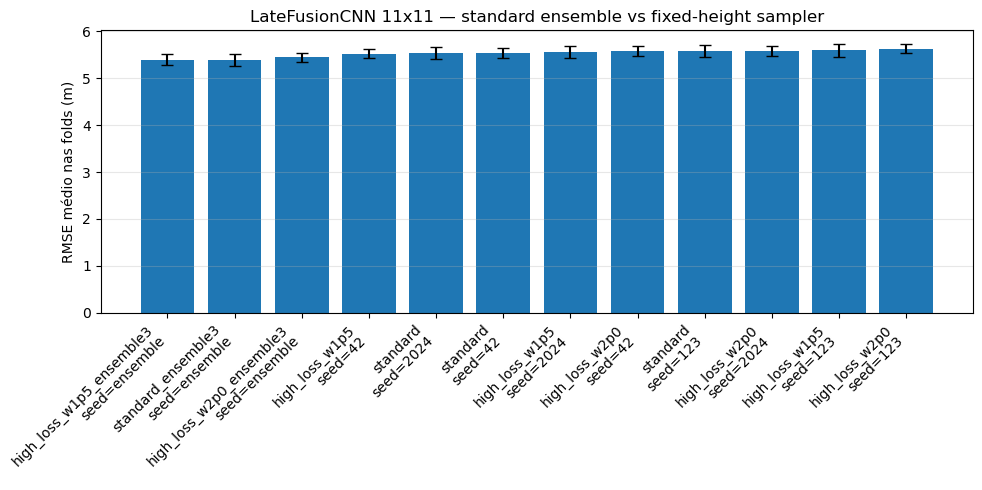

Figura guardada: outputs_fch\spacial_cnn\late_fusion_cnn_11x11_high_weight_loss_ensemble\figuras\bias_por_classe_altura_variantes.png


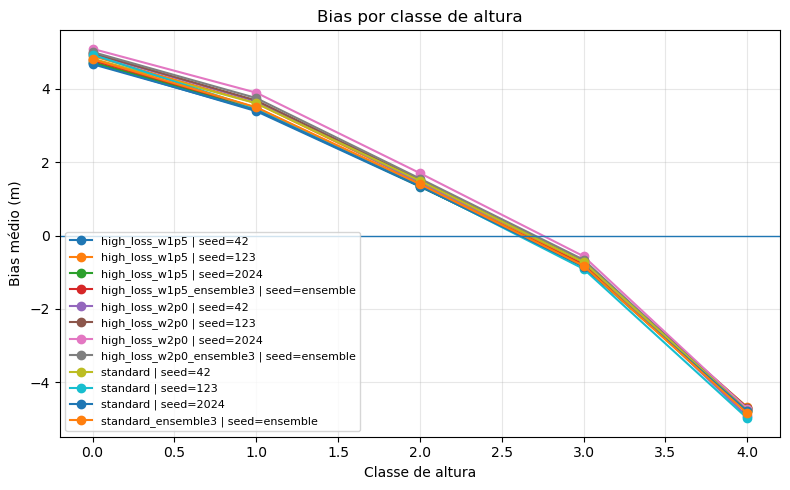

Figura guardada: outputs_fch\spacial_cnn\late_fusion_cnn_11x11_high_weight_loss_ensemble\figuras\scatter_true_vs_pred_high_loss_w1p5_ensemble3_seed_ensemble.png


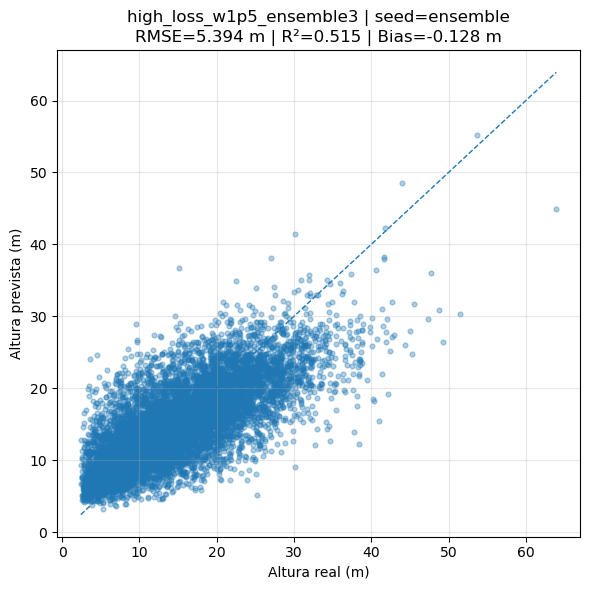

Figura guardada: outputs_fch\spacial_cnn\late_fusion_cnn_11x11_high_weight_loss_ensemble\figuras\scatter_true_vs_pred_high_loss_w2p0_ensemble3_seed_ensemble.png


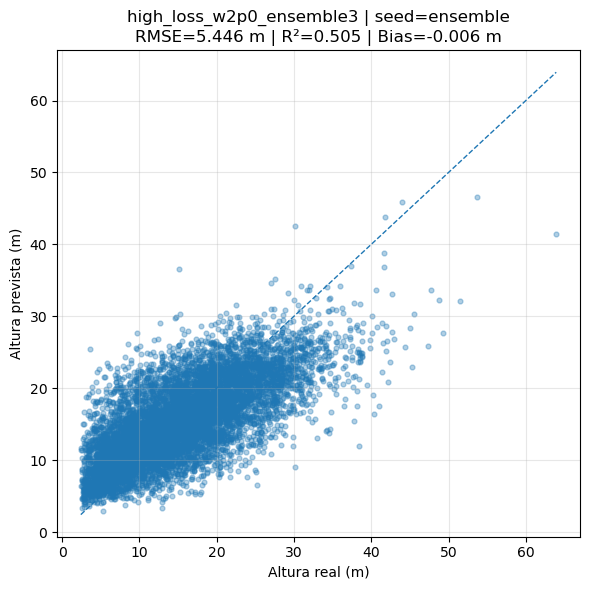

Figura guardada: outputs_fch\spacial_cnn\late_fusion_cnn_11x11_high_weight_loss_ensemble\figuras\scatter_true_vs_pred_standard_ensemble3_seed_ensemble.png


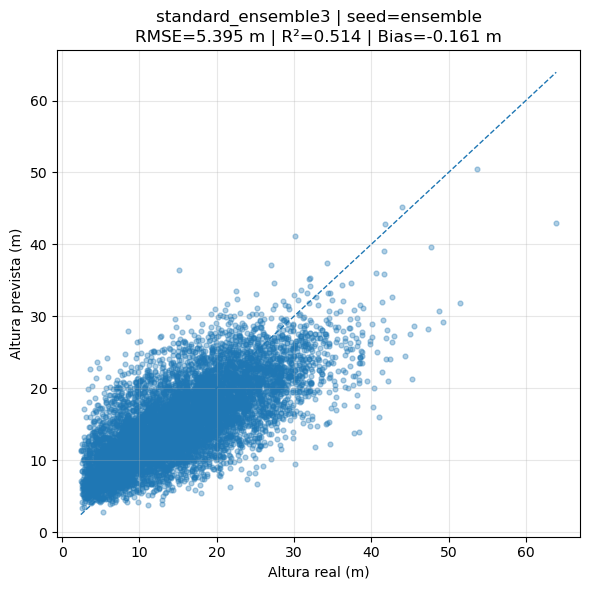


Resultados guardados em: outputs_fch\spacial_cnn\late_fusion_cnn_11x11_high_weight_loss_ensemble


In [24]:
# ============================================================
# 8. PIPELINE — LATEFUSION 11x11 + STANDARD ENSEMBLE + HIGH-HEIGHT WEIGHTED LOSS
# ============================================================

# ------------------------------------------------------------
# Classes de altura e estratificação
# ------------------------------------------------------------

def make_height_classes(y, n_bins=5):
    """
    Cria classes de altura por quantis.

    Com n_bins=5:
      classe 0 = alturas mais baixas
      classe 4 = alturas mais altas
    """
    y = np.asarray(y, dtype=float)

    if len(y) == 0:
        raise ValueError("y está vazio.")

    if len(np.unique(y)) < 2 or n_bins <= 1:
        classes = np.zeros(len(y), dtype=int)
        bins = np.array([np.min(y), np.max(y)])
        return classes, bins

    classes, bins = pd.qcut(
        pd.Series(y),
        q=n_bins,
        labels=False,
        duplicates="drop",
        retbins=True,
    )

    classes = classes.astype(int).to_numpy()
    return classes, bins


def choose_region_height_strata_for_cv(y, regions, n_splits=5, max_bins=5):
    """
    Cria estratos combinados região + classe_altura.

    Isto tenta garantir que cada fold tem:
      - proporção semelhante de pontos de cada região;
      - proporção semelhante de classes de altura;
      - proporção semelhante de cada combinação região/classe_altura.
    """
    y = np.asarray(y, dtype=float)
    regions = np.asarray(regions)

    if len(y) < n_splits:
        raise ValueError(
            f"Dataset tem apenas {len(y)} amostras. "
            f"Não dá para fazer {n_splits} folds."
        )

    max_bins_possible = min(max_bins, len(np.unique(y)), len(y))

    for n_bins in range(max_bins_possible, 0, -1):
        height_classes, bin_edges = make_height_classes(y, n_bins=n_bins)

        strata = np.array([
            f"{region}__h{height_class}"
            for region, height_class in zip(regions, height_classes)
        ])

        counts = pd.Series(strata).value_counts()

        if counts.min() >= n_splits:
            if n_bins < max_bins:
                print(
                    f"AVISO global: reduzi as classes de altura de "
                    f"{max_bins} para {n_bins}, porque havia combinações "
                    f"região/classe_altura com menos de {n_splits} amostras."
                )

            return height_classes, strata, bin_edges

    min_region_count = pd.Series(regions).value_counts().min()

    raise ValueError(
        "Não foi possível criar estratos região + altura para "
        f"{n_splits} folds. A região mais pequena tem {min_region_count} amostras."
    )


def print_height_bins(bin_edges, target_scale=100.0):
    """Mostra os limites das classes de altura em metros."""
    print("\nLimites das classes de altura:")

    for i in range(len(bin_edges) - 1):
        lo = bin_edges[i] / target_scale
        hi = bin_edges[i + 1] / target_scale
        print(f"  Classe {i}: {lo:.2f} m até {hi:.2f} m")


def make_fixed_height_classes(y, bins_m=None, target_scale=100.0):
    """
    Cria classes fixas de altura em metros.

    Por defeito:
      classe 0 = 0-5 m
      classe 1 = 5-10 m
      classe 2 = 10-15 m
      classe 3 = 15-20 m
      classe 4 = >20 m

    A entrada y está em centímetros, como no dataset original.
    """
    if bins_m is None:
        bins_m = FIXED_HEIGHT_BINS_M

    y_m = np.asarray(y, dtype=float) / target_scale
    bins_m = np.asarray(bins_m, dtype=float)

    if not np.isinf(bins_m[-1]):
        raise ValueError("O último limite de bins_m deve ser np.inf.")

    classes = np.digitize(y_m, bins_m[1:-1], right=False).astype(int)

    labels = []
    for i in range(len(bins_m) - 1):
        lo, hi = bins_m[i], bins_m[i + 1]
        if np.isinf(hi):
            labels.append(f">{lo:g} m")
        else:
            labels.append(f"{lo:g}-{hi:g} m")

    return classes, bins_m, labels


def print_fixed_height_bins(bins_m, labels):
    print("\nClasses fixas de altura usadas nas métricas e no sampler:")
    for i, label in enumerate(labels):
        print(f"  Classe {i}: {label}")


def choose_region_fixed_height_strata_for_cv(y, regions, n_splits=5):
    """
    Cria estratos região + classe de altura fixa.

    Se alguma combinação região/classe fixa tiver menos de n_splits amostras,
    usa a versão por quantis apenas para a divisão das folds.
    As métricas e o sampler continuam a usar as classes fixas.
    """
    fixed_classes, bins_m, labels = make_fixed_height_classes(
        y,
        bins_m=FIXED_HEIGHT_BINS_M,
        target_scale=TARGET_SCALE,
    )

    fixed_strata = np.array([
        f"{region}__h{height_class}"
        for region, height_class in zip(regions, fixed_classes)
    ])

    counts = pd.Series(fixed_strata).value_counts()

    if counts.min() >= n_splits:
        print("\nCV: a usar estratificação por região + classes fixas de altura.")
        return fixed_classes, fixed_strata, bins_m, labels, "fixed"

    print("\nAVISO: algumas combinações região + classe fixa têm menos de "
          f"{n_splits} amostras.")
    print("A usar quantis apenas para criar as folds. Métricas e sampler continuam com classes fixas.")

    quantile_classes, quantile_strata, _ = choose_region_height_strata_for_cv(
        y,
        regions,
        n_splits=n_splits,
        max_bins=N_HEIGHT_BINS,
    )

    return fixed_classes, quantile_strata, bins_m, labels, "quantile_for_cv"


# ------------------------------------------------------------
# WeightedRandomSampler
# ------------------------------------------------------------

def make_inverse_frequency_sample_weights(classes):
    """
    Cria pesos inversamente proporcionais à frequência de cada classe.

    Exemplo:
      classe rara  -> peso maior
      classe comum -> peso menor

    Isto não altera a loss. Apenas altera a probabilidade de cada amostra aparecer nos batches.
    """
    classes = np.asarray(classes)
    counts = pd.Series(classes).value_counts().to_dict()

    weights = np.array([
        1.0 / counts[c]
        for c in classes
    ], dtype=np.float64)

    # Normalizar para média 1 melhora a leitura, mas não altera o sampling relativo.
    weights = weights / weights.mean()
    return weights


def print_sampler_diagnostics(train_height_classes, weights):
    """Mostra a distribuição original e os pesos médios por classe no treino."""
    df = pd.DataFrame({
        "height_class": train_height_classes,
        "weight": weights,
    })

    diag = (
        df.groupby("height_class")
        .agg(
            n=("height_class", "size"),
            mean_weight=("weight", "mean"),
            min_weight=("weight", "min"),
            max_weight=("weight", "max"),
        )
        .reset_index()
    )

    print("\nDiagnóstico do WeightedRandomSampler:")
    display(diag)
    return diag


def build_loaders_from_indices(
    X_all,
    y_all,
    train_idx,
    val_idx,
    train_transform=None,
    train_height_classes=None,
    sampling_mode="standard",
    seed=42,
):
    """
    Normaliza sem leakage e cria DataLoaders.

    A média e o desvio padrão são calculados apenas com o treino do fold.
    A validação nunca recebe data augmentation.

    sampling_mode:
      - "standard": shuffle normal.
      - "weighted_sampler": WeightedRandomSampler por classe de altura.
    """
    X_train, X_val, _, _ = normalize_from_train(
        X_all[train_idx],
        X_all[val_idx],
    )

    y_train = y_all[train_idx] / TARGET_SCALE
    y_val = y_all[val_idx] / TARGET_SCALE

    print(
        f"\ny_train: média={y_train.mean():.3f}m | std={y_train.std():.3f}m | "
        f"min={y_train.min():.2f}m | max={y_train.max():.2f}m"
    )
    print(
        f"y_val:   média={y_val.mean():.3f}m | std={y_val.std():.3f}m | "
        f"min={y_val.min():.2f}m | max={y_val.max():.2f}m"
    )

    train_ds = FCHDataset(X_train, y_train, transform=train_transform)
    val_ds = FCHDataset(X_val, y_val)

    generator = torch.Generator()
    generator.manual_seed(seed)

    sampler = None
    shuffle = True

    if sampling_mode == "weighted_sampler":
        if train_height_classes is None:
            train_height_classes, _ = make_height_classes(y_train, n_bins=N_HEIGHT_BINS)

        sample_weights = make_inverse_frequency_sample_weights(train_height_classes)
        print_sampler_diagnostics(train_height_classes, sample_weights)

        sampler = WeightedRandomSampler(
            weights=torch.as_tensor(sample_weights, dtype=torch.double),
            num_samples=len(sample_weights),
            replacement=True,
            generator=generator,
        )
        shuffle = False

    elif sampling_mode == "standard":
        sampler = None
        shuffle = True

    else:
        raise ValueError("sampling_mode deve ser 'standard' ou 'weighted_sampler'.")

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        sampler=sampler,
        drop_last=(len(train_ds) % BATCH_SIZE == 1),
        generator=generator if shuffle else None,
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    return train_loader, val_loader


# ------------------------------------------------------------
# Métricas agrupadas
# ------------------------------------------------------------

def grouped_regression_metrics(predictions_df, group_cols):
    """Calcula métricas agrupadas usando previsões pooled."""
    rows = []

    for group_values, df_group in predictions_df.groupby(group_cols):
        if not isinstance(group_values, tuple):
            group_values = (group_values,)

        metrics = regression_metrics(
            df_group["y_true_m"].to_numpy(),
            df_group["y_pred_m"].to_numpy(),
        )

        row = {col: value for col, value in zip(group_cols, group_values)}
        row.update(metrics)
        rows.append(row)

    return pd.DataFrame(rows)


def summarize_fold_metrics(fold_metrics_df):
    metric_cols = ["RMSE", "%RMSE", "MAE", "R2", "Bias", "Covariancia"]

    summary = (
        fold_metrics_df
        .groupby(["model_variant", "sampling_mode", "loss_mode", "augmentation", "seed"])[metric_cols]
        .agg(["mean", "std"])
        .reset_index()
    )

    return summary


# ------------------------------------------------------------
# Treino de um fold
# ------------------------------------------------------------

def run_fold_for_variant(
    X_all,
    y_all,
    regions_all,
    pids_all,
    height_classes_all,
    sampler_classes_all,
    train_idx,
    val_idx,
    fold,
    model_variant,
    sampling_mode,
    seed,
    train_transform=None,
    loss_config=None,
):
    """Treina e avalia um fold para uma variante experimental."""
    print("\n" + "=" * 80)
    print(
        f" Patch {PATCH_SIZE_TO_USE}x{PATCH_SIZE_TO_USE} | "
        f"{model_variant} | seed={seed} | fold={fold}/{N_SPLITS}"
    )
    print(f"Loss config: {describe_loss_config(loss_config)}")
    print("=" * 80)
    print(f"Treino: {len(train_idx)} amostras")
    print(f"Validação: {len(val_idx)} amostras")
    print(f"Regiões treino: {sorted(set(regions_all[train_idx]))}")
    print(f"Regiões validação: {sorted(set(regions_all[val_idx]))}")

    set_seed(seed)

    train_loader, val_loader = build_loaders_from_indices(
        X_all,
        y_all,
        train_idx,
        val_idx,
        train_transform=train_transform,
        train_height_classes=sampler_classes_all[train_idx] if sampler_classes_all is not None else height_classes_all[train_idx],
        sampling_mode=sampling_mode,
        seed=seed,
    )

    num_channels = X_all.shape[1]
    model = LateFusionSpatialCNN(in_channels=num_channels, channel_groups=CHANNEL_GROUPS)

    print("\nArquitetura: LateFusionSpatialCNN")
    count_parameters(model)

    model_name = (
        f"LateFusionSpatialCNN_patch{PATCH_SIZE_TO_USE}x{PATCH_SIZE_TO_USE}_"
        f"{model_variant}_seed{seed}_fold{fold}"
    )

    model, history = train_spacialcnn_cnn(
        model,
        train_loader,
        val_loader,
        model_name=model_name,
        epochs=EPOCHS,
        patience=PATIENCE,
        lr=LR,
        weight_decay=WEIGHT_DECAY,
        log_every=LOG_EVERY,
        loss_config=loss_config,
    )

    results_df, preds = evaluate_model(
        model,
        val_loader,
        model_name=model_variant,
    )

    results_df["patch_size"] = PATCH_SIZE_TO_USE
    results_df["patch_area_m"] = PATCH_SIZE_TO_USE * 25
    results_df["augmentation"] = AUGMENTATION_MODE
    results_df["sampling_mode"] = sampling_mode
    results_df["loss_mode"] = loss_config.get("loss_mode", "standard") if loss_config else "standard"
    results_df["high_threshold_m"] = loss_config.get("threshold_m", np.nan) if loss_config else np.nan
    results_df["high_weight"] = loss_config.get("high_weight", np.nan) if loss_config else np.nan
    results_df["continuous_alpha"] = loss_config.get("alpha", np.nan) if loss_config else np.nan
    results_df["seed"] = seed
    results_df["fold"] = fold
    results_df["n_train"] = len(train_idx)
    results_df["n_val"] = len(val_idx)

    val_row = results_df[results_df["split"] == "val"].iloc[0]
    print(
        f"\n>>> Validação Final | RMSE={val_row['RMSE']:.3f}m | "
        f"%RMSE={val_row['%RMSE']:.1f}% | MAE={val_row['MAE']:.3f}m | "
        f"R²={val_row['R2']:.3f} | Bias={val_row['Bias']:.3f}m"
    )

    y_true_val = preds["val"]["y_true"]
    y_pred_val = preds["val"]["y_pred"]

    predictions_df = pd.DataFrame({
        "model_variant": model_variant,
        "sampling_mode": sampling_mode,
        "loss_mode": loss_config.get("loss_mode", "standard") if loss_config else "standard",
        "high_threshold_m": loss_config.get("threshold_m", np.nan) if loss_config else np.nan,
        "high_weight": loss_config.get("high_weight", np.nan) if loss_config else np.nan,
        "continuous_alpha": loss_config.get("alpha", np.nan) if loss_config else np.nan,
        "augmentation": AUGMENTATION_MODE,
        "seed": seed,
        "fold": fold,
        "patch_size": PATCH_SIZE_TO_USE,
        "patch_area_m": PATCH_SIZE_TO_USE * 25,
        "region": regions_all[val_idx],
        "point_id": pids_all[val_idx],
        "height_class": height_classes_all[val_idx],
        "y_true_m": y_true_val,
        "y_pred_m": y_pred_val,
    })

    predictions_df["height_class_label"] = predictions_df["height_class"].map(HEIGHT_CLASS_LABEL_MAP)
    predictions_df["residual_m"] = predictions_df["y_pred_m"] - predictions_df["y_true_m"]
    predictions_df["abs_error_m"] = predictions_df["residual_m"].abs()

    history["model_variant"] = model_variant
    history["sampling_mode"] = sampling_mode
    history["loss_mode"] = loss_config.get("loss_mode", "standard") if loss_config else "standard"
    history["high_threshold_m"] = loss_config.get("threshold_m", np.nan) if loss_config else np.nan
    history["high_weight"] = loss_config.get("high_weight", np.nan) if loss_config else np.nan
    history["continuous_alpha"] = loss_config.get("alpha", np.nan) if loss_config else np.nan
    history["seed"] = seed
    history["fold"] = fold

    del model, train_loader, val_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return results_df, history, predictions_df


# ------------------------------------------------------------
# Ensemble
# ------------------------------------------------------------

def build_ensemble_predictions(individual_predictions_df, model_variant, sampling_mode, seeds):
    """Cria previsões ensemble por média das previsões das várias seeds."""
    df = individual_predictions_df[
        (individual_predictions_df["model_variant"] == model_variant)
        & (individual_predictions_df["sampling_mode"] == sampling_mode)
        & (individual_predictions_df["seed"].isin(seeds))
    ].copy()

    if df.empty:
        return pd.DataFrame()

    group_cols = [
        "augmentation",
        "fold",
        "patch_size",
        "patch_area_m",
        "region",
        "point_id",
        "height_class",
        "height_class_label",
        "y_true_m",
    ]

    ensemble_df = (
        df.groupby(group_cols, as_index=False)["y_pred_m"]
        .mean()
    )

    ensemble_df["model_variant"] = f"{model_variant}_ensemble{len(seeds)}"
    ensemble_df["sampling_mode"] = sampling_mode

    # Propagar metadados da loss. Estes valores são constantes dentro de cada model_variant.
    meta_cols = ["loss_mode", "high_threshold_m", "high_weight", "continuous_alpha"]
    for col in meta_cols:
        if col in df.columns:
            vals = df[col].dropna().unique()
            ensemble_df[col] = vals[0] if len(vals) > 0 else np.nan

    ensemble_df["seed"] = "ensemble"
    ensemble_df["residual_m"] = ensemble_df["y_pred_m"] - ensemble_df["y_true_m"]
    ensemble_df["abs_error_m"] = ensemble_df["residual_m"].abs()

    ordered_cols = [
        "model_variant",
        "sampling_mode",
        "loss_mode",
        "high_threshold_m",
        "high_weight",
        "continuous_alpha",
        "augmentation",
        "seed",
        "fold",
        "patch_size",
        "patch_area_m",
        "region",
        "point_id",
        "height_class",
        "height_class_label",
        "y_true_m",
        "y_pred_m",
        "residual_m",
        "abs_error_m",
    ]

    return ensemble_df[ordered_cols]


def metrics_by_fold_from_predictions(predictions_df):
    group_cols = [
        "model_variant",
        "sampling_mode",
        "loss_mode",
        "augmentation",
        "seed",
        "fold",
    ]
    return grouped_regression_metrics(predictions_df, group_cols=group_cols)

# ------------------------------------------------------------
# Gráficos simples finais
# ------------------------------------------------------------

def plot_rmse_comparison(fold_metrics_df):
    plot_df = (
        fold_metrics_df
        .groupby(["model_variant", "seed"])["RMSE"]
        .agg(["mean", "std"])
        .reset_index()
    )

    plot_df["label"] = plot_df["model_variant"].astype(str) + "\nseed=" + plot_df["seed"].astype(str)
    plot_df = plot_df.sort_values("mean")

    plt.figure(figsize=(10, 5))
    x = np.arange(len(plot_df))
    plt.bar(x, plot_df["mean"], yerr=plot_df["std"], capsize=4)
    plt.xticks(x, plot_df["label"], rotation=45, ha="right")
    plt.ylabel("RMSE médio nas folds (m)")
    plt.title("LateFusionCNN 11x11 — standard ensemble vs fixed-height sampler")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    fig_path = PLOTS_DIR / "comparacao_rmse_variantes.png"
    plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    print(f"Figura guardada: {fig_path}")
    plt.show()


def plot_bias_by_height_class(predictions_df):
    metric_df = grouped_regression_metrics(
        predictions_df,
        group_cols=["model_variant", "seed", "height_class"],
    )

    plt.figure(figsize=(8, 5))

    for (model_variant, seed), df_group in metric_df.groupby(["model_variant", "seed"]):
        df_group = df_group.sort_values("height_class")
        label = f"{model_variant} | seed={seed}"
        plt.plot(df_group["height_class"], df_group["Bias"], marker="o", label=label)

    plt.axhline(0, linewidth=1)
    plt.xlabel("Classe de altura")
    plt.ylabel("Bias médio (m)")
    plt.title("Bias por classe de altura")
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)
    plt.tight_layout()

    fig_path = PLOTS_DIR / "bias_por_classe_altura_variantes.png"
    plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    print(f"Figura guardada: {fig_path}")
    plt.show()


def plot_true_vs_pred_for_model(predictions_df, model_variant, seed):
    df = predictions_df[
        (predictions_df["model_variant"] == model_variant)
        & (predictions_df["seed"].astype(str) == str(seed))
    ].copy()

    if df.empty:
        print(f"Sem dados para {model_variant}, seed={seed}")
        return

    metrics = regression_metrics(df["y_true_m"], df["y_pred_m"])

    plt.figure(figsize=(6, 6))
    plt.scatter(df["y_true_m"], df["y_pred_m"], alpha=0.35, s=12)

    mn = min(df["y_true_m"].min(), df["y_pred_m"].min())
    mx = max(df["y_true_m"].max(), df["y_pred_m"].max())
    plt.plot([mn, mx], [mn, mx], linestyle="--", linewidth=1)

    plt.xlabel("Altura real (m)")
    plt.ylabel("Altura prevista (m)")
    plt.title(
        f"{model_variant} | seed={seed}\n"
        f"RMSE={metrics['RMSE']:.3f} m | R²={metrics['R2']:.3f} | Bias={metrics['Bias']:.3f} m"
    )
    plt.grid(alpha=0.3)
    plt.tight_layout()

    safe_model = re.sub(r"[^A-Za-z0-9_]+", "_", str(model_variant))
    safe_seed = re.sub(r"[^A-Za-z0-9_]+", "_", str(seed))
    fig_path = PLOTS_DIR / f"scatter_true_vs_pred_{safe_model}_seed_{safe_seed}.png"
    plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    print(f"Figura guardada: {fig_path}")
    plt.show()


# ============================================================
# 9. CARREGAMENTO DOS DADOS 11x11
# ============================================================

print("=" * 80)
print(" LATE FUSION CNN 11x11 — STANDARD ENSEMBLE + HIGH-HEIGHT WEIGHTED LOSS")
print("=" * 80)

X_all, y_all, regions_all, pids_all, band_names_ref = load_all_regions_tifs(
    RAW_BASE_DIR,
    VALIDATION_DIR,
    target_column=TARGET_COLUMN,
)

print(f"\nX_all: {X_all.shape}")
print(f"y_all: {y_all.shape}")
print(f"Regiões: {sorted(np.unique(regions_all))}")
print(f"N amostras: {len(y_all)}")

CHANNEL_GROUPS = infer_late_fusion_channel_groups(band_names_ref)

height_classes, strata, fixed_bins_m, height_class_labels, cv_strata_source = choose_region_fixed_height_strata_for_cv(
    y_all,
    regions_all,
    n_splits=N_SPLITS,
)

HEIGHT_CLASS_LABEL_MAP = {i: label for i, label in enumerate(height_class_labels)}
print_fixed_height_bins(fixed_bins_m, height_class_labels)
print(f"Origem dos estratos da CV: {cv_strata_source}")

# Guardar distribuição dos dados.
data_distribution_df = pd.DataFrame({
    "region": regions_all,
    "point_id": pids_all,
    "y_cm": y_all,
    "y_m": y_all / TARGET_SCALE,
    "height_class": height_classes,
    "height_class_label": [HEIGHT_CLASS_LABEL_MAP[c] for c in height_classes],
    "stratum": strata,
    "cv_strata_source": cv_strata_source,
})

data_distribution_df.to_csv(
    OUTPUT_BASE_DIR / "dataset_distribution_11x11.csv",
    index=False,
)

print("\n=== Distribuição por região ===")
display(data_distribution_df["region"].value_counts().rename_axis("region").reset_index(name="n"))

print("\n=== Distribuição por classe de altura ===")
display(data_distribution_df["height_class"].value_counts().sort_index().rename_axis("height_class").reset_index(name="n"))

print("\n=== Distribuição região × classe de altura ===")
display(pd.crosstab(data_distribution_df["region"], data_distribution_df["height_class"]))


# ============================================================
# 10. FOLDS CV
# ============================================================

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED,
)

cv_splits = list(skf.split(X_all, strata))

fold_ids = np.full(len(y_all), fill_value=-1, dtype=int)
for fold, (_, val_idx) in enumerate(cv_splits, start=1):
    fold_ids[val_idx] = fold

fold_assignments_df = data_distribution_df.copy()
fold_assignments_df["fold"] = fold_ids
fold_assignments_df["patch_size"] = PATCH_SIZE_TO_USE
fold_assignments_df["patch_area_m"] = PATCH_SIZE_TO_USE * 25

fold_assignments_df.to_csv(
    OUTPUT_BASE_DIR / "fold_assignments_cv_global_misturado_11x11.csv",
    index=False,
)

print("\n=== Distribuição de regiões por fold ===")
display(pd.crosstab(fold_assignments_df["fold"], fold_assignments_df["region"]))

print("\n=== Distribuição de classes de altura por fold ===")
display(pd.crosstab(fold_assignments_df["fold"], fold_assignments_df["height_class"]))


# ============================================================
# 11. DEFINIR EXPERIÊNCIAS
# ============================================================

experiments = []

if RUN_STANDARD_ENSEMBLE:
    experiments.append({
        "model_variant": "standard",
        "sampling_mode": "standard",
        "seeds": ENSEMBLE_SEEDS,
        "sampler_classes_all": None,
        "loss_config": {"loss_mode": "standard"},
    })

if RUN_HIGH_HEIGHT_WEIGHTED_LOSS:
    for high_weight in HIGH_HEIGHT_WEIGHTS_TO_RUN:
        safe_weight = str(high_weight).replace(".", "p")
        experiments.append({
            "model_variant": f"high_loss_w{safe_weight}",
            "sampling_mode": "standard",
            "seeds": ENSEMBLE_SEEDS,
            "sampler_classes_all": None,
            "loss_config": {
                "loss_mode": "high_weight",
                "threshold_m": HIGH_HEIGHT_THRESHOLD_M,
                "high_weight": float(high_weight),
            },
        })

if RUN_CONTINUOUS_HEIGHT_WEIGHTED_LOSS:
    y_max_train_global_m = float(np.max(y_all / TARGET_SCALE))

    for alpha in CONTINUOUS_HEIGHT_ALPHAS_TO_RUN:
        safe_alpha = str(alpha).replace(".", "p")
        experiments.append({
            "model_variant": f"continuous_loss_alpha{safe_alpha}",
            "sampling_mode": "standard",
            "seeds": ENSEMBLE_SEEDS,
            "sampler_classes_all": None,
            "loss_config": {
                "loss_mode": "continuous",
                "alpha": float(alpha),
                "y_max_train_m": y_max_train_global_m,
            },
        })

print("\nExperiências a correr:")
for exp in experiments:
    print(
        f"  {exp['model_variant']} | sampling={exp['sampling_mode']} | "
        f"seeds={exp['seeds']} | loss={describe_loss_config(exp['loss_config'])}"
    )

train_transform = get_train_transform(AUGMENTATION_MODE)


# ============================================================
# 12. TREINO
# ============================================================

all_results = []
all_predictions = []
all_histories = []

for exp in experiments:
    model_variant = exp["model_variant"]
    sampling_mode = exp["sampling_mode"]
    seeds = exp["seeds"]
    sampler_classes_all = exp.get("sampler_classes_all")
    loss_config = exp.get("loss_config", {"loss_mode": "standard"})

    for seed in seeds:
        for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
            results_df, history_df, predictions_df = run_fold_for_variant(
                X_all=X_all,
                y_all=y_all,
                regions_all=regions_all,
                pids_all=pids_all,
                height_classes_all=height_classes,
                sampler_classes_all=sampler_classes_all,
                train_idx=train_idx,
                val_idx=val_idx,
                fold=fold,
                model_variant=model_variant,
                sampling_mode=sampling_mode,
                seed=seed,
                train_transform=train_transform,
                loss_config=loss_config,
            )

            all_results.append(results_df)
            all_predictions.append(predictions_df)
            all_histories.append(history_df)

individual_results_df = pd.concat(all_results, ignore_index=True)
individual_predictions_df = pd.concat(all_predictions, ignore_index=True)
all_histories_df = pd.concat(all_histories, ignore_index=True)

individual_results_df.to_csv(
    OUTPUT_BASE_DIR / "resultados_individuais_por_seed_fold.csv",
    index=False,
)

individual_predictions_df.to_csv(
    OUTPUT_BASE_DIR / "predicoes_individuais_por_seed.csv",
    index=False,
)

all_histories_df.to_csv(
    OUTPUT_BASE_DIR / "historicos_treino_por_seed_fold.csv",
    index=False,
)

print("\n=== Resultados individuais por seed/fold ===")
display(individual_results_df)


# ============================================================
# 13. ENSEMBLE DAS SEEDS
# ============================================================

ensemble_predictions_list = []

for exp in experiments:
    if len(exp["seeds"]) <= 1:
        continue

    ens_df = build_ensemble_predictions(
        individual_predictions_df,
        model_variant=exp["model_variant"],
        sampling_mode=exp["sampling_mode"],
        seeds=exp["seeds"],
    )

    if not ens_df.empty:
        ensemble_predictions_list.append(ens_df)

if ensemble_predictions_list:
    ensemble_predictions_df = pd.concat(ensemble_predictions_list, ignore_index=True)
else:
    ensemble_predictions_df = pd.DataFrame()

ensemble_predictions_df.to_csv(
    OUTPUT_BASE_DIR / "predicoes_ensemble.csv",
    index=False,
)

# Para comparação final: modelos individuais + ensembles.
all_predictions_for_comparison = pd.concat(
    [individual_predictions_df, ensemble_predictions_df],
    ignore_index=True,
)

all_predictions_for_comparison.to_csv(
    OUTPUT_BASE_DIR / "TODAS_predicoes_comparacao.csv",
    index=False,
)


# ============================================================
# 14. MÉTRICAS FINAIS
# ============================================================

fold_metrics_df = metrics_by_fold_from_predictions(all_predictions_for_comparison)
fold_metrics_df.to_csv(
    OUTPUT_BASE_DIR / "metricas_por_fold_todos_modelos.csv",
    index=False,
)

summary_metrics_df = summarize_fold_metrics(fold_metrics_df)
summary_metrics_df.to_csv(
    OUTPUT_BASE_DIR / "comparacao_modelos_media_std_folds.csv",
    index=False,
)

metrics_by_region_df = grouped_regression_metrics(
    all_predictions_for_comparison,
    group_cols=["model_variant", "sampling_mode", "loss_mode", "augmentation", "seed", "region"],
)
metrics_by_region_df.to_csv(
    OUTPUT_BASE_DIR / "metricas_por_regiao_pooled.csv",
    index=False,
)

metrics_by_height_class_df = grouped_regression_metrics(
    all_predictions_for_comparison,
    group_cols=["model_variant", "sampling_mode", "loss_mode", "augmentation", "seed", "height_class", "height_class_label"],
)
metrics_by_height_class_df.to_csv(
    OUTPUT_BASE_DIR / "metricas_por_classe_altura_pooled.csv",
    index=False,
)

print("\n=== Métricas por fold — todos os modelos ===")
display(fold_metrics_df)

print("\n=== Comparação final — média ± std das folds ===")
display(summary_metrics_df)

print("\n=== Métricas por região — pooled predictions ===")
display(metrics_by_region_df)

print("\n=== Métricas por classe de altura — pooled predictions ===")
display(metrics_by_height_class_df)


# ============================================================
# 15. GRÁFICOS FINAIS
# ============================================================

plot_rmse_comparison(fold_metrics_df)
plot_bias_by_height_class(all_predictions_for_comparison)

# Scatter das versões ensemble, quando existirem.
if not ensemble_predictions_df.empty:
    for ens_model in sorted(ensemble_predictions_df["model_variant"].unique()):
        plot_true_vs_pred_for_model(
            all_predictions_for_comparison,
            model_variant=ens_model,
            seed="ensemble",
        )

print(f"\nResultados guardados em: {OUTPUT_BASE_DIR}")
